# Cairo Weather Forecast — Data Acquisition & Time-Series EDA

**Project goal:** build a reproducible ML-ready weather dataset for Cairo, with daily meteorological observations from 2021 through the project cutoff (2026-10-12), and use temperature as the prediction target. The latest row with a valid temperature target is 2026-10-10 because NASA POWER returned a fill value for the requested cutoff date.

- **Region:** Cairo, Egypt — latitude 30.0444, longitude 31.2357
- **API:** [NASA POWER Daily API](https://power.larc.nasa.gov/docs/services/api/temporal/daily/), a free public API with historical and near-real-time data
- **Sampling:** every 2 days after downloading the complete daily API response; this preserves the full time range while keeping the final dataset in the requested 1,000–1,500-row range
- **Final dataset:** outputs/cairo_weather_2021_2026_2day.csv
- **Target:** target_temperature_c = NASA POWER T2M, daily average air temperature at 2 m in °C

NASA POWER allows up to 20 parameters per point request. The API response is downloaded in yearly chunks, then converted into one clean CSV containing the requested meteorological variables plus calendar and cyclical features.

## The 10 questions answered by this notebook

### Part 2 — Prepare the Time-Series Dataset
1. **What does the dataset structure look like?** Are dates ordered, regularly sampled, duplicated, or missing?
2. **How should missing values and anomalies be handled?** Are there API fill values, impossible physical ranges, or late-window gaps?

### Part 3 — Exploratory Data Analysis (EDA)
3. **What is the overall distribution of target temperature?** What are the center, spread, and extreme values?
4. **Does Cairo temperature have a long-term trend?** Is the rolling baseline increasing or decreasing?
5. **When is Cairo hottest?** What does the monthly and seasonal cycle look like?
6. **Does local variability change over time?** Are some periods more volatile than others?
7. **What are the trend, seasonal, and residual components?** What does STL reveal?
8. **Does temperature depend on previous observations?** What do ACF and PACF show?
9. **Is the target stationary?** What do raw, first-difference, and seasonal-difference ADF tests imply?
10. **How do other weather variables correlate with temperature?** Which relationships are useful and which risk leakage?

The notebook also includes a final ML handoff section with a chronological, leakage-aware train/test split.

In [38]:
from pathlib import Path
import json
import time
import warnings

import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import linregress
from statsmodels.tsa.seasonal import STL
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.stattools import adfuller

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (12, 5)
plt.rcParams["axes.titlesize"] = 14
plt.rcParams["axes.labelsize"] = 11

PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == "outputs" and (PROJECT_ROOT.parent / "outputs").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
DATA_PATH = PROJECT_ROOT / "outputs" / "cairo_weather_2021_2026_2day.csv"
RAW_DIR = PROJECT_ROOT / ".work" / "raw"
RAW_DIR.mkdir(parents=True, exist_ok=True)
START_DATE = "2021-01-01"
END_DATE = "2026-10-12"
LATITUDE = 30.0444
LONGITUDE = 31.2357
SAMPLE_EVERY_N_DAYS = 2

print(f"Project root: {PROJECT_ROOT}")
print(f"Expected data file: {DATA_PATH}")

Project root: d:\ML_Intern\Weather_Forecast
Expected data file: d:\ML_Intern\Weather_Forecast\outputs\cairo_weather_2021_2026_2day.csv


## 1. API design and reproducible data acquisition

The request uses UTC daily values. The API is queried once per calendar year to make retries easier and to avoid an unnecessarily large response. The 20 requested POWER parameters are mapped to readable column names in the CSV. NASA POWER uses -999 as a fill value; the parser converts it to missing values before saving the final data.

In [39]:
API_ENDPOINT = "https://power.larc.nasa.gov/api/temporal/daily/point"
API_PARAMS = [
    "T2M", "T2M_MAX", "T2M_MIN", "T2MDEW", "T2MWET", "RH2M",
    "PRECTOTCORR", "WS10M", "WS10M_MAX", "WS10M_MIN", "WD10M",
    "WS50M", "WS50M_MAX", "WS50M_MIN", "WD50M", "PS", "QV2M",
    "ALLSKY_SFC_SW_DWN", "ALLSKY_SFC_LW_DWN", "CLRSKY_SFC_SW_DWN"
]

PARAMETER_DESCRIPTIONS = {
    "T2M": "daily average air temperature at 2 m (°C)",
    "T2M_MAX": "daily maximum air temperature at 2 m (°C)",
    "T2M_MIN": "daily minimum air temperature at 2 m (°C)",
    "T2MDEW": "dew-point temperature at 2 m (°C)",
    "T2MWET": "wet-bulb temperature at 2 m (°C)",
    "RH2M": "relative humidity at 2 m (%)",
    "PRECTOTCORR": "bias-corrected precipitation (mm/day)",
    "WS10M": "wind speed at 10 m (m/s)",
    "WS10M_MAX": "maximum wind speed at 10 m (m/s)",
    "WS10M_MIN": "minimum wind speed at 10 m (m/s)",
    "WD10M": "wind direction at 10 m (degrees)",
    "WS50M": "wind speed at 50 m (m/s)",
    "WS50M_MAX": "maximum wind speed at 50 m (m/s)",
    "WS50M_MIN": "minimum wind speed at 50 m (m/s)",
    "WD50M": "wind direction at 50 m (degrees)",
    "PS": "surface pressure (kPa)",
    "QV2M": "specific humidity at 2 m (g/kg)",
    "ALLSKY_SFC_SW_DWN": "all-sky surface shortwave radiation (MJ/m²/day)",
    "ALLSKY_SFC_LW_DWN": "all-sky surface longwave radiation (MJ/m²/day)",
    "CLRSKY_SFC_SW_DWN": "clear-sky surface shortwave radiation (MJ/m²/day)",
}


def api_url(start_date, end_date):
    params = {
        "parameters": ",".join(API_PARAMS),
        "community": "RE",
        "longitude": LONGITUDE,
        "latitude": LATITUDE,
        "start": pd.Timestamp(start_date).strftime("%Y%m%d"),
        "end": pd.Timestamp(end_date).strftime("%Y%m%d"),
        "format": "JSON",
        "time-standard": "UTC",
    }
    return API_ENDPOINT, params


def fetch_year(year, start_date, end_date, force_download=False):
    raw_path = RAW_DIR / f"nasa_power_cairo_{year}.json"
    if raw_path.exists() and raw_path.stat().st_size > 100 and not force_download:
        with raw_path.open("r", encoding="utf-8") as f:
            return json.load(f)
    url, params = api_url(start_date, end_date)
    for attempt in range(3):
        try:
            response = requests.get(url, params=params, timeout=180)
            response.raise_for_status()
            data = response.json()
            raw_path.write_text(json.dumps(data, indent=2), encoding="utf-8")
            return data
        except Exception:
            if attempt == 2:
                raise
            time.sleep(2 * (attempt + 1))


def collect_raw_api_data(force_download=False):
    all_dates = {}
    for year in range(pd.Timestamp(START_DATE).year, pd.Timestamp(END_DATE).year + 1):
        year_start = max(pd.Timestamp(START_DATE), pd.Timestamp(f"{year}-01-01"))
        year_end = min(pd.Timestamp(END_DATE), pd.Timestamp(f"{year}-12-31"))
        payload = fetch_year(year, year_start.strftime("%Y-%m-%d"), year_end.strftime("%Y-%m-%d"), force_download)
        params = payload["properties"]["parameter"]
        for date_key in params["T2M"]:
            all_dates.setdefault(date_key, {})
            for parameter in API_PARAMS:
                value = params.get(parameter, {}).get(date_key, np.nan)
                all_dates[date_key][parameter] = np.nan if value == -999 else value
    return pd.DataFrame.from_dict(all_dates, orient="index").sort_index()

# Set to True only when a fresh API download is needed.
# raw_api_df = collect_raw_api_data(force_download=False)
# raw_api_df.head()

> The download cell is intentionally reproducible but commented by default because the cleaned CSV is already included with this notebook. Uncomment it to re-query NASA POWER. The final CSV is the single tabular data file used by the analysis.

In [40]:
df = pd.read_csv(DATA_PATH, parse_dates=["date"])
df = df.sort_values("date").reset_index(drop=True)
df.head()

,date,target_temperature_c,temperature_max_c,temperature_min_c,dew_point_c,wet_bulb_temperature_c,relative_humidity_pct,precipitation_mm_day,wind_speed_10m_m_s,wind_speed_10m_max_m_s,...,day_of_year,day_of_week,is_weekend,season,temperature_range_c,dewpoint_depression_c,wind_u_10m_m_s,wind_v_10m_m_s,day_of_year_sin,day_of_year_cos
0,2021-01-01,14.84,21.54,8.75,9.41,12.13,72.16,0.0,3.00,3.86,...,1,5,0,Winter,12.79,5.43,1.805445,2.395907,0.017202,0.999852
1,2021-01-03,15.12,22.70,9.62,10.37,12.75,75.31,0.0,3.20,4.28,...,3,0,1,Winter,13.08,4.75,2.056920,2.451342,0.051584,0.998669
2,2021-01-05,17.09,25.26,11.81,9.31,13.20,63.75,0.0,2.53,3.58,...,5,2,0,Winter,13.45,7.78,-1.414758,2.097465,0.085906,0.996303
3,2021-01-07,18.22,27.25,12.36,5.36,11.79,46.34,0.0,3.43,4.67,...,7,4,0,Winter,14.89,12.86,-2.876640,1.868112,0.120126,0.992759
4,2021-01-09,15.94,24.69,10.20,6.00,10.97,57.90,0.0,3.10,3.96,...,9,6,1,Winter,14.49,9.94,0.270183,-3.088204,0.154204,0.988039


In [41]:
print("Shape:", df.shape)
print("Date range:", df["date"].min().date(), "to", df["date"].max().date())
print("Number of columns:", len(df.columns))
print("Number of non-target predictors:", len([c for c in df.columns if c not in {"date", "target_temperature_c"}]))
assert 1000 <= len(df) <= 1500, "The requested row range is not satisfied."
assert "target_temperature_c" in df.columns, "Temperature target is missing."
assert len([c for c in df.columns if c not in {"date", "target_temperature_c", "season"}]) >= 20

df.info()

Shape: (1055, 33)
Date range: 2021-01-01 to 2026-10-10
Number of columns: 33
Number of non-target predictors: 31
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1055 entries, 0 to 1054
Data columns (total 33 columns):
 #   Column                         Non-Null Count  Dtype         
---  ------                         --------------  -----         
 0   date                           1055 non-null   datetime64[ns]
 1   target_temperature_c           1055 non-null   float64       
 2   temperature_max_c              1055 non-null   float64       
 3   temperature_min_c              1055 non-null   float64       
 4   dew_point_c                    1055 non-null   float64       
 5   wet_bulb_temperature_c         1055 non-null   float64       
 6   relative_humidity_pct          1055 non-null   float64       
 7   precipitation_mm_day           1055 non-null   float64       
 8   wind_speed_10m_m_s             1055 non-null   float64       
 9   wind_speed_10m_max_m_s         1055 no

## Part 2 — Prepare the Time-Series Dataset

Part 2 converts the raw API response into a trustworthy sequential table before any visual interpretation. It parses dates, sorts the observations, checks the expected two-day sampling interval, detects duplicate timestamps, verifies units, and quantifies missing values per column. API fill values are converted to NaN rather than being treated as real weather. Short internal gaps in continuous numeric measurements are interpolated in time and the before/after missing-cell counts are reported. The target is never fabricated; a date without a valid target is excluded from the modeling table.

**Questions answered here:**
- **Q1:** What does the dataset structure look like?
- **Q2:** How should missing values and anomalies be handled?

In [42]:
df = df.replace([-999, -999.0], np.nan)
duplicated_dates = int(df["date"].duplicated().sum())
df = df.set_index("date").sort_index()
frequency_counts = df.index.to_series().diff().value_counts().head()
missing_before = df.isna().sum().sort_values(ascending=False)

negative_precip = int((df["precipitation_mm_day"] < 0).sum())
invalid_relative_humidity = int(((df["relative_humidity_pct"] < 0) | (df["relative_humidity_pct"] > 100)).sum())
invalid_wind_speed = int((df[["wind_speed_10m_m_s", "wind_speed_50m_m_s"]] < 0).any(axis=1).sum())
invalid_temperature_order = int((df["temperature_min_c"] > df["temperature_max_c"]).sum())

numeric_cols = df.select_dtypes(include=np.number).columns.tolist()
missing_cells_before = int(df[numeric_cols].isna().sum().sum())
df[numeric_cols] = df[numeric_cols].interpolate(method="time", limit=2, limit_direction="both")
missing_cells_after = int(df[numeric_cols].isna().sum().sum())

quality_report = pd.Series({
    "duplicate_dates": duplicated_dates,
    "most_common_time_step": str(frequency_counts.index[0]) if len(frequency_counts) else "not available",
    "missing_numeric_cells_before": missing_cells_before,
    "missing_numeric_cells_after": missing_cells_after,
    "negative_precipitation_values": negative_precip,
    "humidity_out_of_range": invalid_relative_humidity,
    "negative_wind_speed_values": invalid_wind_speed,
    "min_above_max_temperature_rows": invalid_temperature_order,
})
quality_report

duplicate_dates                                 0
most_common_time_step             2 days 00:00:00
missing_numeric_cells_before                  108
missing_numeric_cells_after                   102
negative_precipitation_values                   0
humidity_out_of_range                           0
negative_wind_speed_values                      0
min_above_max_temperature_rows                  0
dtype: object

In [43]:
print("Missing values per column (before interpolation):")
display(missing_before[missing_before > 0].to_frame("missing_count"))

print("Time-step counts:")
display(frequency_counts.to_frame("count"))

print("Quality report:")
display(quality_report.to_frame("value"))

Missing values per column (before interpolation):


,missing_count
all_sky_longwave_mj_m2_day,36
clear_sky_shortwave_mj_m2_day,36
all_sky_shortwave_mj_m2_day,36


Time-step counts:


,count
date,
2 days,1054


Quality report:


,value
duplicate_dates,0
most_common_time_step,2 days 00:00:00
missing_numeric_cells_before,108
missing_numeric_cells_after,102
negative_precipitation_values,0
humidity_out_of_range,0
negative_wind_speed_values,0
min_above_max_temperature_rows,0


## Part 3 — Exploratory Data Analysis (EDA)

Part 3 moves from data integrity to evidence. Each visual answers one question about the target temperature and its time-dependent structure. The analysis combines descriptive distributions, time-aware trend and seasonality views, rolling statistics, STL decomposition, autocorrelation, stationarity tests, correlations, and anomaly diagnostics. These plots are designed to explain what the model should learn, not just to display generic summaries.

,count,mean,std,min,25%,50%,75%,max
target_temperature_c,1055.0,22.490,6.939,6.570,15.810,23.220,29.085,35.010
temperature_max_c,1055.0,30.391,7.658,11.790,23.345,31.310,37.425,45.490
temperature_min_c,1055.0,15.487,5.970,2.110,9.945,16.040,20.875,26.610
relative_humidity_pct,1055.0,51.465,13.068,16.550,42.120,49.880,61.405,85.390
precipitation_mm_day,1055.0,0.241,1.479,0.000,0.000,0.000,0.010,26.030
wind_speed_10m_m_s,1055.0,3.976,0.988,1.270,3.335,3.920,4.580,7.980
surface_pressure_kpa,1055.0,99.790,0.471,98.550,99.425,99.750,100.120,101.230
all_sky_shortwave_mj_m2_day,1021.0,5.773,1.828,1.089,4.001,5.987,7.517,8.504


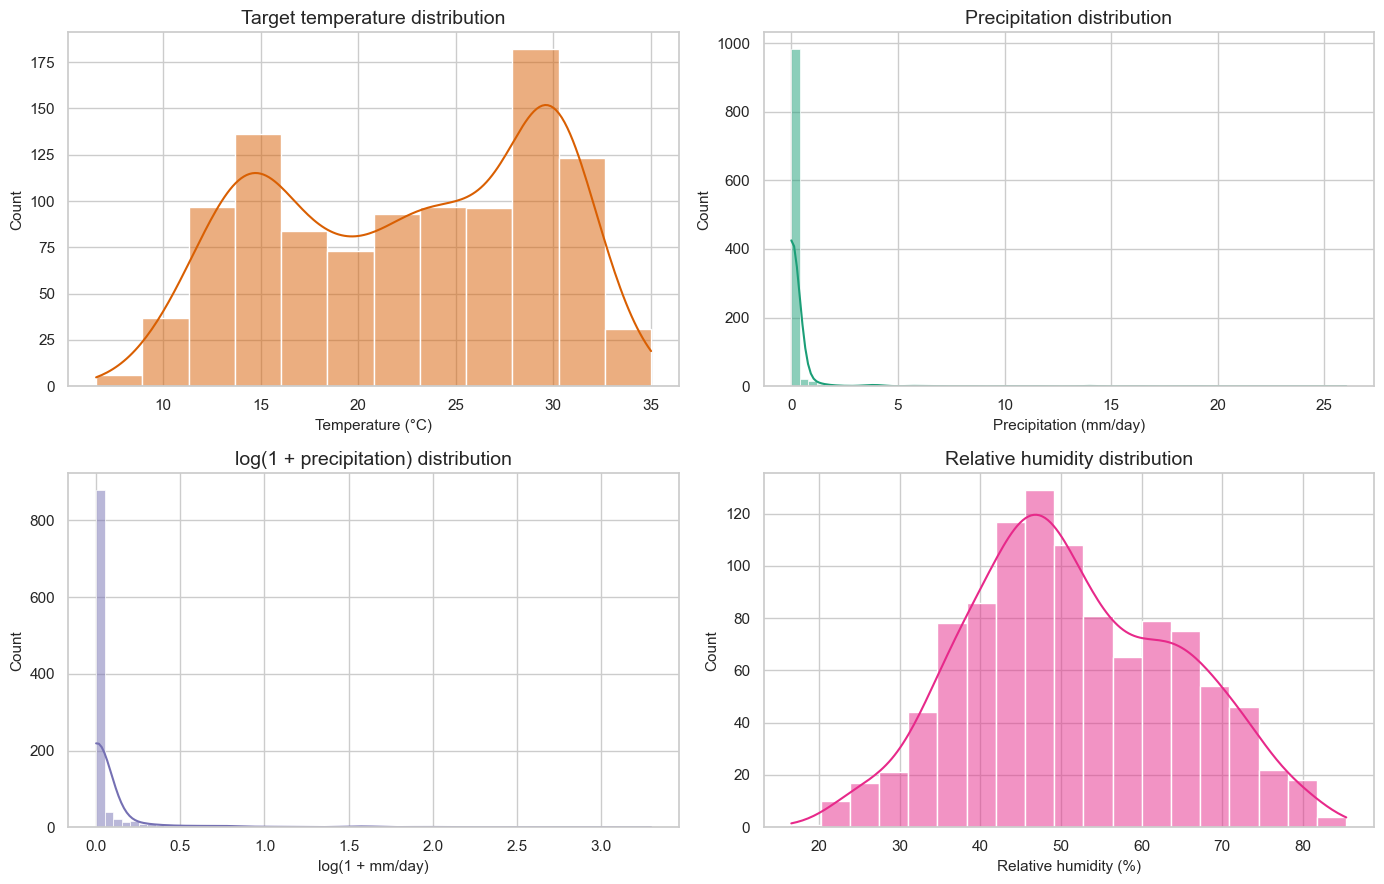

In [44]:
summary_cols = [
    "target_temperature_c", "temperature_max_c", "temperature_min_c", "relative_humidity_pct",
    "precipitation_mm_day", "wind_speed_10m_m_s", "surface_pressure_kpa",
    "all_sky_shortwave_mj_m2_day"
]
display(df[summary_cols].describe().T.round(3))

fig, axes = plt.subplots(2, 2, figsize=(14, 9))
sns.histplot(df["target_temperature_c"], kde=True, ax=axes[0, 0], color="#d95f02")
axes[0, 0].set_title("Target temperature distribution")
axes[0, 0].set_xlabel("Temperature (°C)")
sns.histplot(df["precipitation_mm_day"], kde=True, ax=axes[0, 1], color="#1b9e77")
axes[0, 1].set_title("Precipitation distribution")
axes[0, 1].set_xlabel("Precipitation (mm/day)")
sns.histplot(np.log1p(df["precipitation_mm_day"]), kde=True, ax=axes[1, 0], color="#7570b3")
axes[1, 0].set_title("log(1 + precipitation) distribution")
axes[1, 0].set_xlabel("log(1 + mm/day)")
sns.histplot(df["relative_humidity_pct"], kde=True, ax=axes[1, 1], color="#e7298a")
axes[1, 1].set_title("Relative humidity distribution")
axes[1, 1].set_xlabel("Relative humidity (%)")
plt.tight_layout()

### Question 4 — Does Cairo temperature have a long-term trend, and does local variability change over time?

The 30-day rolling mean highlights the slow baseline and the 30-day rolling standard deviation highlights local volatility. A simple linear fit is used as a descriptive trend estimate, not as a climate attribution.

Estimated linear slope: 0.493 °C per year
Two-sided trend p-value: 0.0001127


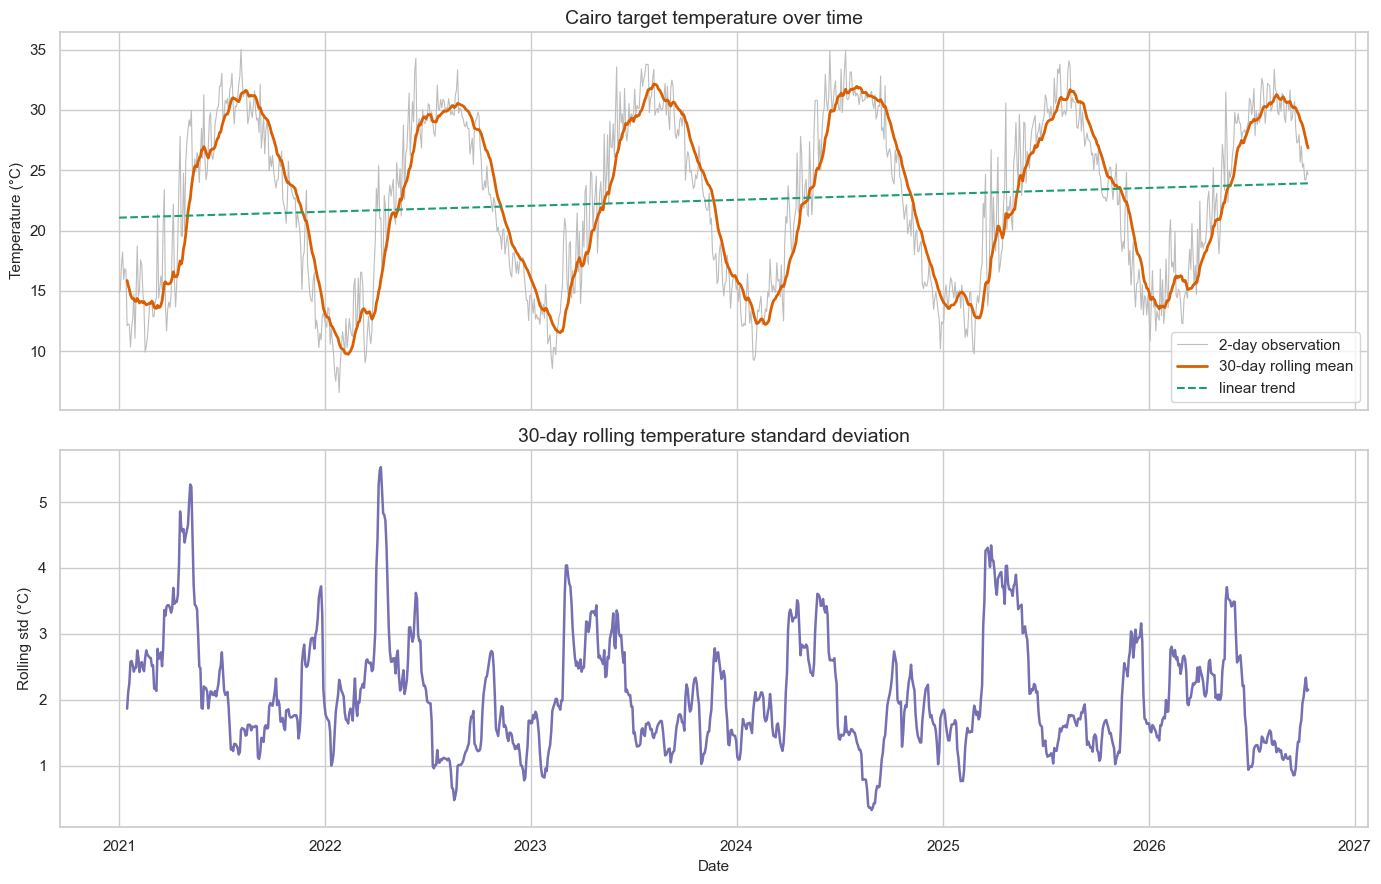

In [45]:
series = df["target_temperature_c"]
time_index = np.arange(len(series))
trend_fit = linregress(time_index, series.values)
trend_per_year = trend_fit.slope * 365.25 / SAMPLE_EVERY_N_DAYS
print(f"Estimated linear slope: {trend_per_year:.3f} °C per year")
print(f"Two-sided trend p-value: {trend_fit.pvalue:.4g}")

rolling_mean = series.rolling(window=15, min_periods=8).mean()  # about 30 days at 2-day sampling
rolling_std = series.rolling(window=15, min_periods=8).std()

fig, axes = plt.subplots(2, 1, figsize=(14, 9), sharex=True)
axes[0].plot(df.index, series, color="#bdbdbd", linewidth=0.8, label="2-day observation")
axes[0].plot(df.index, rolling_mean, color="#d95f02", linewidth=2, label="30-day rolling mean")
axes[0].plot(df.index, np.polyval(np.polyfit(time_index, series.values, 1), time_index), color="#1b9e77", linestyle="--", label="linear trend")
axes[0].set_title("Cairo target temperature over time")
axes[0].set_ylabel("Temperature (°C)")
axes[0].legend()
axes[1].plot(df.index, rolling_std, color="#7570b3", linewidth=1.8)
axes[1].set_title("30-day rolling temperature standard deviation")
axes[1].set_ylabel("Rolling std (°C)")
axes[1].set_xlabel("Date")
plt.tight_layout()

### Question 5 — When is Cairo hottest? (Seasonality)

Monthly boxplots and monthly means show the annual cycle. This is the main reason the raw target should not be treated as a featureless stationary signal.

,count,mean,std,min,max
season,,,,,
Autumn,247,24.40,4.05,15.11,32.81
Spring,276,20.98,4.99,9.03,31.46
Summer,276,30.30,1.81,24.22,35.01
Winter,256,13.86,2.46,6.57,20.89


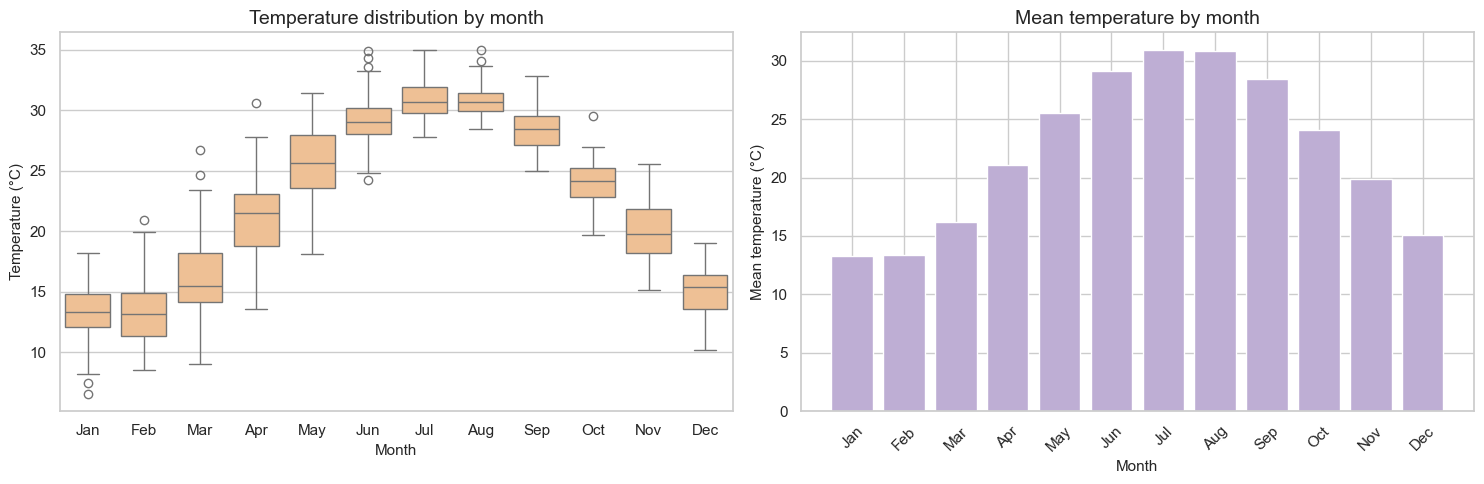

In [46]:
month_order = list(range(1, 13))
month_labels = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
plot_df = df.copy()
plot_df["month_name"] = pd.Categorical(plot_df["month"].map(dict(zip(month_order, month_labels))), categories=month_labels, ordered=True)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.boxplot(data=plot_df, x="month_name", y="target_temperature_c", ax=axes[0], color="#fdc086")
axes[0].set_title("Temperature distribution by month")
axes[0].set_xlabel("Month")
axes[0].set_ylabel("Temperature (°C)")
monthly_mean = plot_df.groupby("month_name", observed=True)["target_temperature_c"].mean()
axes[1].bar(monthly_mean.index, monthly_mean.values, color="#beaed4")
axes[1].set_title("Mean temperature by month")
axes[1].set_xlabel("Month")
axes[1].set_ylabel("Mean temperature (°C)")
axes[1].tick_params(axis="x", rotation=45)
plt.tight_layout()

display(df.groupby("season")["target_temperature_c"].agg(["count", "mean", "std", "min", "max"]).round(2))

### Question 7 — What are the trend, seasonal, and residual components?

STL decomposition uses an annual period of approximately 182 observations because the dataset is sampled every two days. The robust option reduces the influence of isolated extremes.

,variance
observed,48.145
trend,0.118
seasonal,44.140
residual,3.523


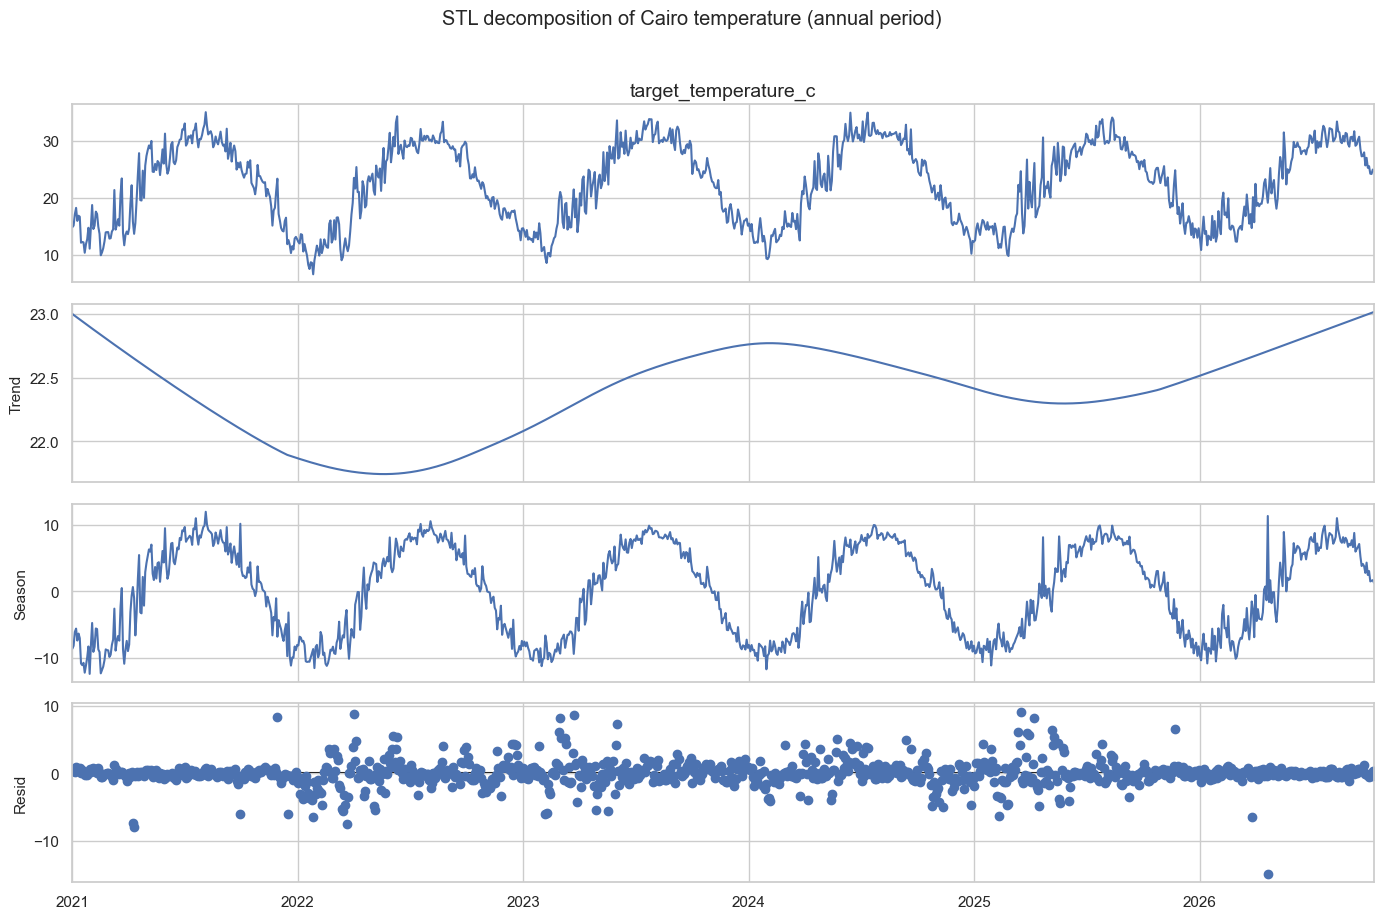

In [47]:
stl = STL(df["target_temperature_c"], period=182, robust=True).fit()
fig = stl.plot()
fig.set_size_inches(14, 9)
fig.suptitle("STL decomposition of Cairo temperature (annual period)", y=1.02)
plt.tight_layout()

component_variance = pd.Series({
    "observed": df["target_temperature_c"].var(),
    "trend": stl.trend.var(),
    "seasonal": stl.seasonal.var(),
    "residual": stl.resid.var(),
}).round(3)
display(component_variance.to_frame("variance"))

### Question 8 — Does temperature depend on previous observations?

ACF measures total lag dependence while PACF isolates the direct effect of each lag after accounting for shorter lags. Peaks around the annual lag support seasonality.

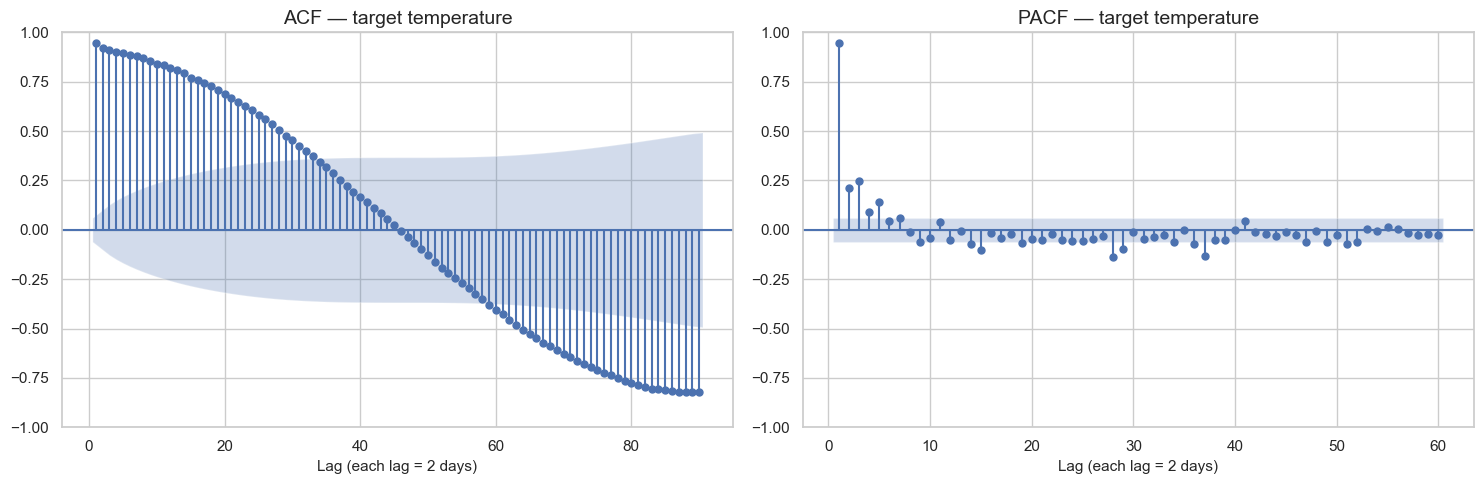

In [48]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
plot_acf(df["target_temperature_c"].dropna(), lags=90, ax=axes[0], zero=False)
axes[0].set_title("ACF — target temperature")
axes[0].set_xlabel("Lag (each lag = 2 days)")
plot_pacf(df["target_temperature_c"].dropna(), lags=60, ax=axes[1], zero=False, method="ywm")
axes[1].set_title("PACF — target temperature")
axes[1].set_xlabel("Lag (each lag = 2 days)")
plt.tight_layout()

### Question 9 — Is the target stationary?

The Augmented Dickey–Fuller test is applied to the raw target, its first difference, and its annual seasonal difference. The result guides whether later models need differencing or can use explicit seasonal features.

In [49]:
def adf_result(values, label):
    values = pd.Series(values).dropna()
    result = adfuller(values, autolag="AIC")
    return pd.Series({
        "series": label,
        "ADF statistic": result[0],
        "p-value": result[1],
        "lags used": result[2],
        "observations": result[3],
        "interpretation": "stationary at 5%" if result[1] < 0.05 else "fail to reject non-stationarity at 5%",
    })

adf_table = pd.DataFrame([
    adf_result(df["target_temperature_c"], "raw target"),
    adf_result(df["target_temperature_c"].diff(), "first difference"),
    adf_result(df["target_temperature_c"].diff(182), "annual seasonal difference"),
]).set_index("series")
display(adf_table.round(4))

,ADF statistic,p-value,lags used,observations,interpretation
series,,,,,
raw target,-4.0603,0.0011,22,1032,stationary at 5%
first difference,-7.9575,0.0000,13,1040,stationary at 5%
annual seasonal difference,-7.5288,0.0000,10,862,stationary at 5%


### Question 10 — How do other weather variables correlate with temperature?

The correlation matrix and pair plots describe relationships among temperature, humidity, precipitation, wind, pressure, and radiation. Correlation is used for feature screening, not as causal proof, and same-day variables are kept out of a leakage-safe forecast design.

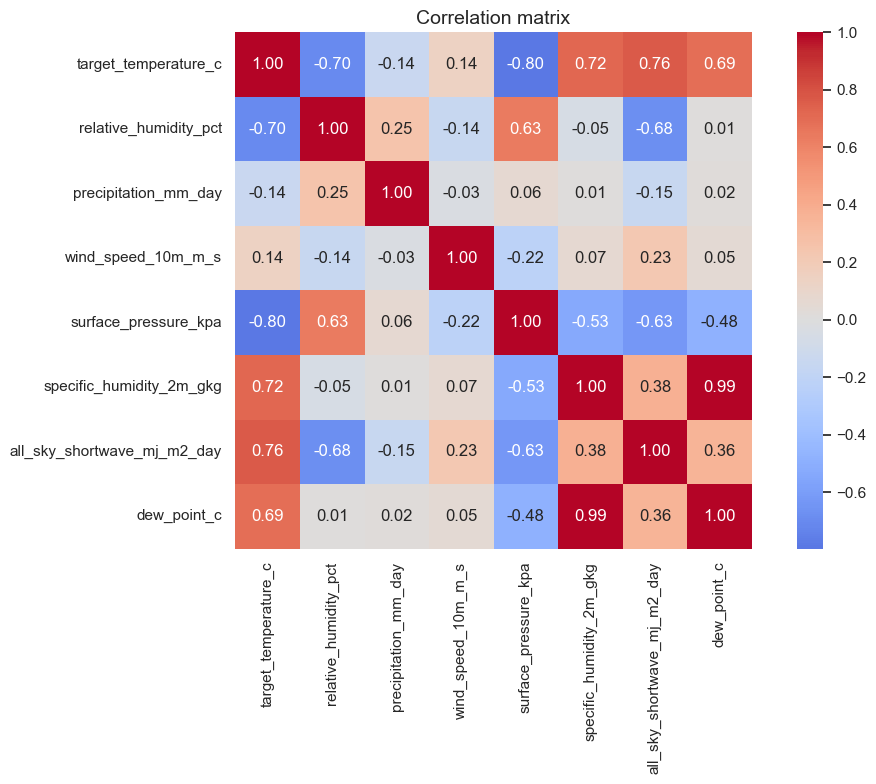

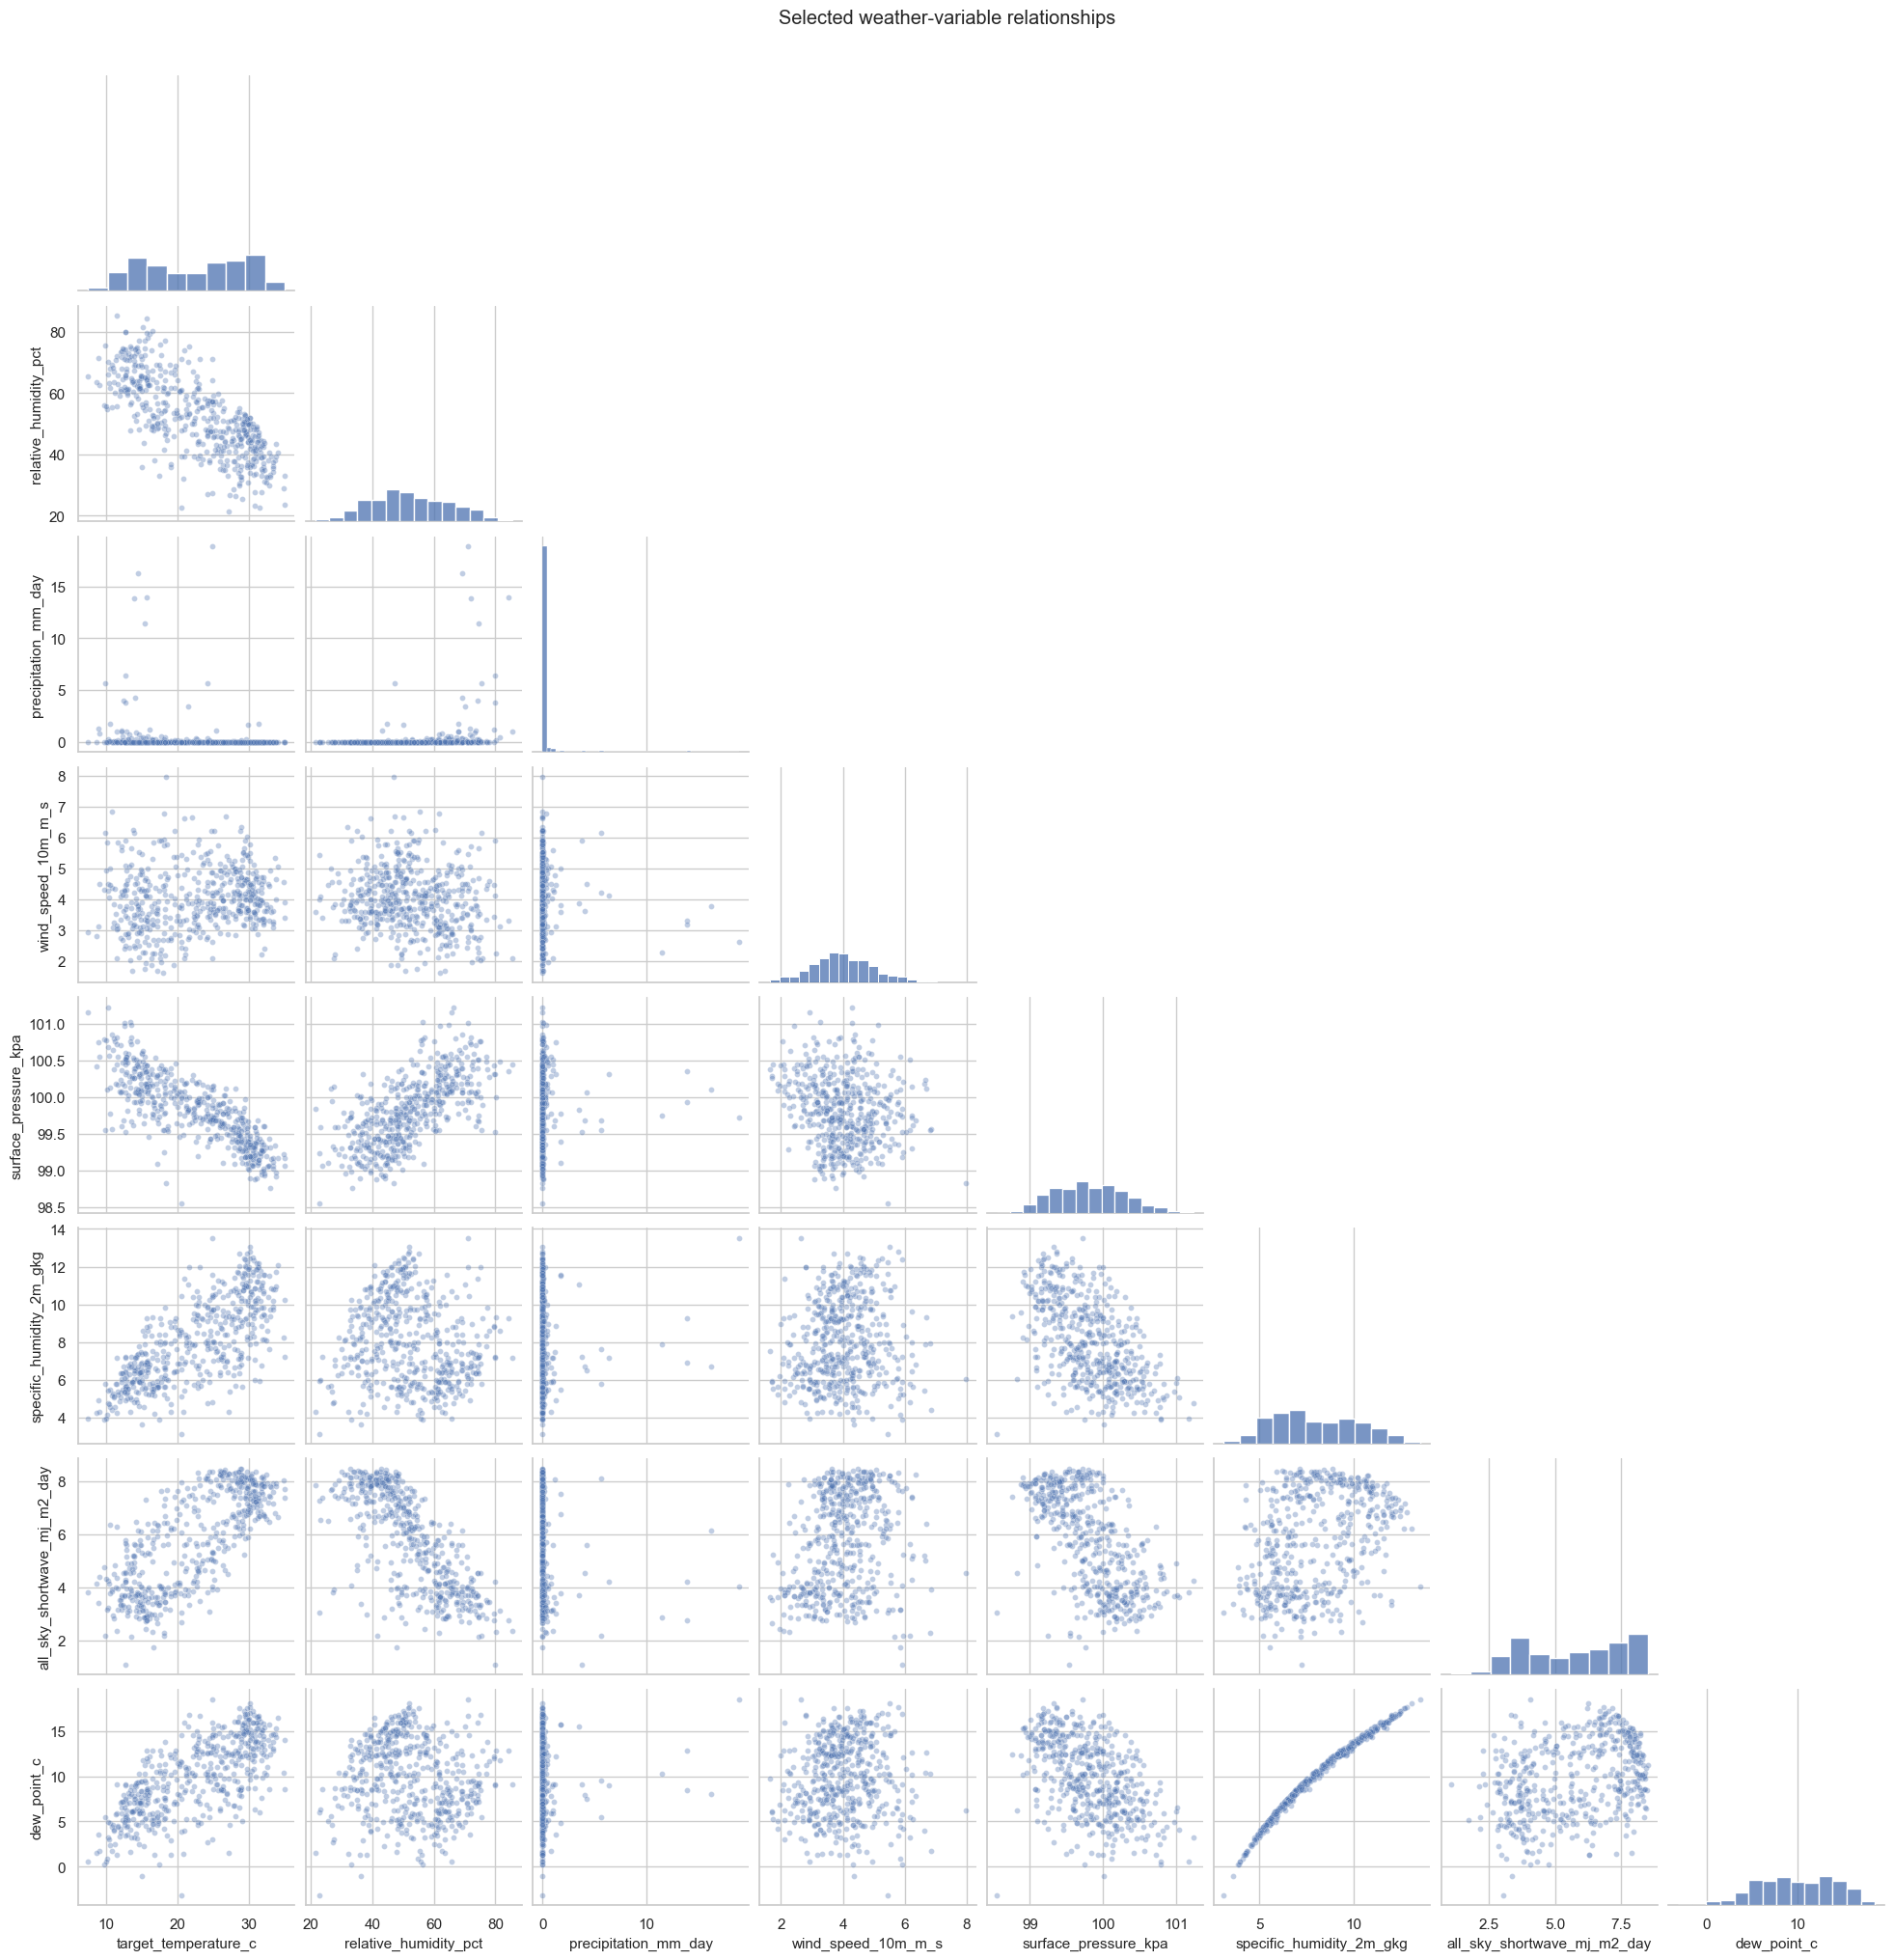

In [50]:
relationship_cols = [
    "target_temperature_c", "relative_humidity_pct", "precipitation_mm_day",
    "wind_speed_10m_m_s", "surface_pressure_kpa", "specific_humidity_2m_gkg",
    "all_sky_shortwave_mj_m2_day", "dew_point_c"
]
correlation = df[relationship_cols].corr(numeric_only=True)
plt.figure(figsize=(11, 8))
sns.heatmap(correlation, annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True)
plt.title("Correlation matrix")
plt.tight_layout()

g = sns.pairplot(df[relationship_cols].sample(min(500, len(df)), random_state=42), corner=True, plot_kws={"alpha": 0.35, "s": 18})
g.fig.suptitle("Selected weather-variable relationships", y=1.02)
plt.show()

## Supporting diagnostic — anomaly and physical-range review

This section supports the ten questions by flagging locally unusual temperatures and impossible domain values before modeling.

Local temperature anomalies with |rolling z| > 3: 0
Negative precipitation values: 0
Humidity outside [0, 100]: 0
Min temperature above max temperature: 0


,target_temperature_c,temperature_rolling_z,relative_humidity_pct,precipitation_mm_day
date,,,,


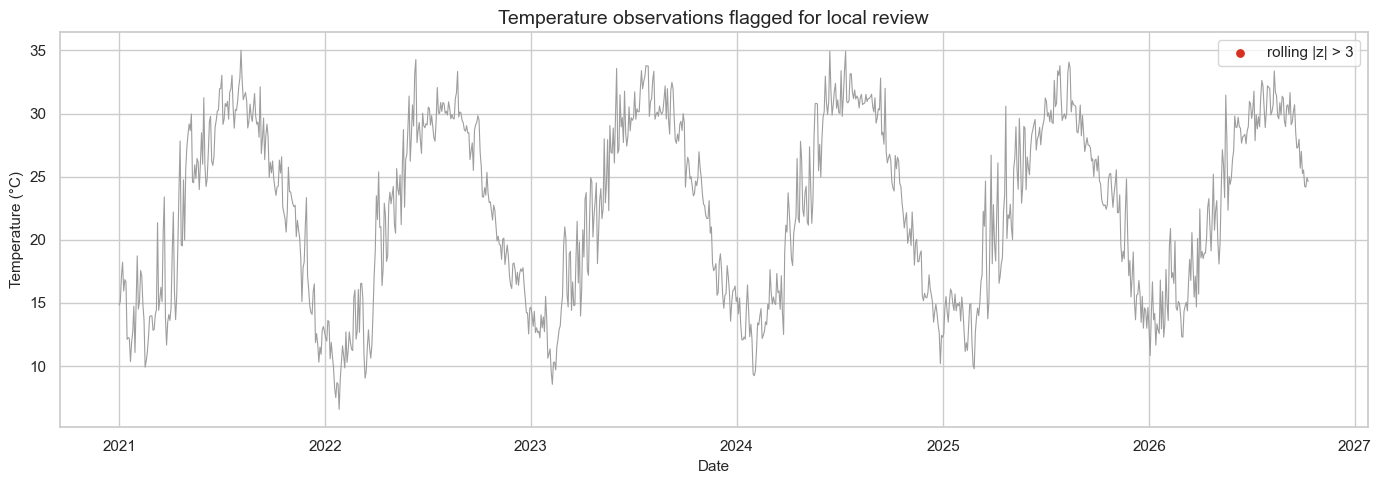

In [51]:
local_mean = series.rolling(15, min_periods=10).mean()
local_std = series.rolling(15, min_periods=10).std()
rolling_z = (series - local_mean) / local_std.replace(0, np.nan)
df["temperature_rolling_z"] = rolling_z
anomaly_mask = rolling_z.abs() > 3
anomalies = df.loc[anomaly_mask, ["target_temperature_c", "temperature_rolling_z", "relative_humidity_pct", "precipitation_mm_day"]].copy()
anomalies = anomalies.sort_values("temperature_rolling_z", key=np.abs, ascending=False)

print(f"Local temperature anomalies with |rolling z| > 3: {len(anomalies)}")
print(f"Negative precipitation values: {int((df['precipitation_mm_day'] < 0).sum())}")
print(f"Humidity outside [0, 100]: {int(((df['relative_humidity_pct'] < 0) | (df['relative_humidity_pct'] > 100)).sum())}")
print(f"Min temperature above max temperature: {int((df['temperature_min_c'] > df['temperature_max_c']).sum())}")
display(anomalies.head(10))

plt.figure(figsize=(14, 5))
plt.plot(df.index, series, linewidth=0.8, color="#9e9e9e")
plt.scatter(anomalies.index, anomalies["target_temperature_c"], color="#d7301f", s=28, label="rolling |z| > 3")
plt.title("Temperature observations flagged for local review")
plt.xlabel("Date")
plt.ylabel("Temperature (°C)")
plt.legend()
plt.tight_layout()

## ML handoff — chronological, leakage-aware split

This final section is not an additional EDA question. It turns the findings into a modeling setup with lagged target/exogenous variables and a chronological train/test split.

In [52]:
ml = df.copy()
base_exogenous = [
    "relative_humidity_pct", "precipitation_mm_day", "wind_speed_10m_m_s",
    "wind_direction_10m_deg", "surface_pressure_kpa", "specific_humidity_2m_gkg",
    "all_sky_shortwave_mj_m2_day", "all_sky_longwave_mj_m2_day",
    "clear_sky_shortwave_mj_m2_day", "month", "day_of_year_sin", "day_of_year_cos",
    "is_weekend"
]
for lag in [1, 2, 7]:
    ml[f"target_lag_{lag}"] = ml["target_temperature_c"].shift(lag)
for col in base_exogenous:
    ml[f"{col}_lag_1"] = ml[col].shift(1)

feature_cols = [c for c in ml.columns if c.startswith("target_lag_") or c.endswith("_lag_1")]
model_df = ml[feature_cols + ["target_temperature_c"]].dropna()
split_point = int(len(model_df) * 0.8)
X_train = model_df[feature_cols].iloc[:split_point]
y_train = model_df["target_temperature_c"].iloc[:split_point]
X_test = model_df[feature_cols].iloc[split_point:]
y_test = model_df["target_temperature_c"].iloc[split_point:]

print("Feature count:", len(feature_cols))
print("Train period:", X_train.index.min().date(), "to", X_train.index.max().date())
print("Test period:", X_test.index.min().date(), "to", X_test.index.max().date())
print("X_train:", X_train.shape, "X_test:", X_test.shape)
print("No random shuffle was used; the test set is later in time.")

Feature count: 16
Train period: 2021-01-15 to 2025-06-25
Test period: 2025-06-27 to 2026-08-05
X_train: (812, 16) X_test: (203, 16)
No random shuffle was used; the test set is later in time.


## Main conclusions to record after running

- The final table has the requested 1,000–1,500 observations and at least 20 usable predictors, with target_temperature_c as the target.
- The 2-day sampling choice is documented because downloading every day from 2021 through the cutoff would exceed the requested row range.
- Use the rolling-trend, monthly boxplot, STL, ACF/PACF, ADF, correlation heatmap, and anomaly report together rather than relying on one plot.
- Before fitting a production forecasting model, check the API's latest-data availability, preserve chronological validation, and avoid same-day leakage from variables only known after the target day.